# Initalize libraries

## Import libraries

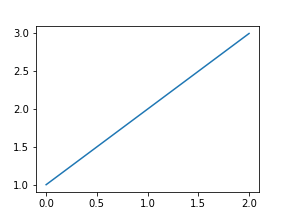

In [2]:
%matplotlib widget

import matplotlib

matplotlib.rcParams["figure.dpi"] = 72
matplotlib.rcParams["figure.figsize"] = (4, 3)

import matplotlib.pyplot as plt

plt.plot([1, 2, 3])
plt.show()

In [3]:
import matplotlib
import ipympl
import ipywidgets

print("matplotlib:", matplotlib.__version__)
print("ipympl:", ipympl.__version__)
print("ipywidgets:", ipywidgets.__version__)
print("backend:", matplotlib.get_backend())

matplotlib: 3.9.1
ipympl: 0.9.7
ipywidgets: 8.1.7
backend: widget


In [4]:
## do some kernel inspections and check backend and frontend for widget functionality

import ipywidgets
import ipympl
import matplotlib
import sys
import site

print(sys.executable)
site.getsitepackages()
site.getusersitepackages()
#print(site.ENABLE_USER_SITE)    # this should be False. it means that installations do not go into ./local , but only in the venv
site.ENABLE_USER_SITE == False

#print(matplotlib.get_backend())
print("ipywidgets:", ipywidgets.__version__)
print("ipympl:", ipympl.__version__)
print("matplotlib:", matplotlib.__version__)
print("python:", __import__("sys").executable)
#print("widgetsnbextension:", widgetsnbextension.__version__)
#print("jupyterlab_widgets:", jupyterlab_widgets.__version__)
#print("backend:", matplotlib.get_backend())


# print('If the widget interactive operations are not working, it is likely due to a version mismatch between matplotlib, ipywidgets nad ipympl. Working configuration is: \
# mamba install -y \
#   ipympl=0.9.7 \
#   matplotlib=3.9.1 \
#   ipywidgets=8.1.7 )


print("""
-----------------------------------
If widget interactive operations are not working, it is likely due to a version mismatch between matplotlib, ipywidgets, and ipympl.

Working configuration:

matplotlib = 3.9.1
ipympl = 0.9.7
ipywidgets = 8.1.7
widgetsnbextension = 4.0.14
jupyterlab_widgets = 3.0.15

Environment:
/asap3/petra3/gpfs/p04/2025/data/11020879/shared/venv

Activation:
mamba activate /asap3/petra3/gpfs/p04/2025/data/11020879/shared/venv
""")

/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/bin/python
ipywidgets: 8.1.7
ipympl: 0.9.7
matplotlib: 3.9.1
python: /asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/bin/python

-----------------------------------
If widget interactive operations are not working, it is likely due to a version mismatch between matplotlib, ipywidgets, and ipympl.

Working configuration:

matplotlib = 3.9.1
ipympl = 0.9.7
ipywidgets = 8.1.7
widgetsnbextension = 4.0.14
jupyterlab_widgets = 3.0.15

Environment:
/asap3/petra3/gpfs/p04/2025/data/11020879/shared/venv

Activation:
mamba activate /asap3/petra3/gpfs/p04/2025/data/11020879/shared/venv



If widget interactive operations are not working, do the following: 
* in terminal, go to environment

```
   . mamba-init
   mamba activate /asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv   ( or similar environment)

   mamba install -y \
      matplotlib=3.9.1 \
      ipympl=0.9.7 \
      ipywidgets=8.1.7 \
      jupyterlab_widgets=3.0.15 \
      widgetsnbextension=4.0.14
```

struggled with that in the past. Also, if this fix does not work, either make a clean install #

```
mamba deactivate

rm -rf /asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv

mamba create -p /asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv \
  python=3.11 \
  matplotlib=3.9.1 \
  ipympl=0.9.7 \
  ipywidgets=8.1.7 \
  jupyterlab_widgets=3.0.15 \
  widgetsnbextension=4.0.14

mamba activate /asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv
mamba install -y ipykernel

```

... and then create kernel, or copy last working version of python venv.


additional packages:

Scientific:
```
mamba install -y \
  numpy scipy h5py imageio xarray \
  matplotlib pillow tqdm \
  scikit-image scikit-learn \
  pyqt qtpy \
  pip
```

Reconstruction:
```
mamba install -y \
  pyfai silx fabio \
  nexusformat \
  pyopencl ocl-icd-system
```

cuda:
```
mamba install -y cupy-cuda12x
```
or (if not working)
```
python -m pip install wand cupy-cuda13x nexusformat dipy
```

For the GPU versioning (Tesla P100):
```
python -m pip uninstall -y cupy-cuda12x
python -m pip install cupy-cuda11x
```

optional if still not working
```
export CUDA_HOME=/usr/local/cuda
export CUDA_PATH=/usr/local/cuda
export CUDA_VISIBLE_DEVICES=0
export CUPY_CACHE_DIR=$HOME/.cupy_cache
```



In [5]:
# general
import gc
import json
import os
import shutil
import sys
import time
from getpass import getuser
from glob import glob
from importlib import reload
from multiprocessing import Pool
from os import path
from os.path import join

import h5py
import imageio

# Plotting
import matplotlib.pyplot as plt
import numpy as np

# pyFAI
import pyFAI
import scipy

# skimage
import skimage.morphology

# Data
import xarray as xr
from nexusformat.nexus import *
from PIL import Image
from pyFAI.azimuthalIntegrator import AzimuthalIntegrator
from pyFAI.detectors import Detector
from scipy import stats
from scipy.interpolate import griddata

# scipy
from scipy.ndimage import gaussian_filter
from skimage.draw import ellipse
from tqdm.auto import tqdm

# Self-written libraries
sys.path.append(join(os.getcwd(), "library"))
import fthcore as fth
import helper_functions as helper
import interactive
import mask_lib
import reconstruct as reco
import reconstruct_rb as rec
from interactive import cimshow

plt.rcParams["figure.constrained_layout.use"] = True  # replaces plt.tight_layout

  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start
    self.asyncio_loop.run_forever()
  File "/asap3/petra3

In [6]:
# Is there a GPU?
try:
    # Cupy
    import cupy as cp
    import cupyx as cpx

    GPU = True

    print("GPU available")

    # Self-written library
    import CCI_core_cupy as cci
    import Phase_Retrieval as PhR
except:
    GPU = False
    import CCI_core as cci

    print("GPU unavailable")

GPU available


In [7]:
# interactive plotting
import ipywidgets

%matplotlib widget

# Auto formatting of cells
# %load_ext jupyter_black

In [8]:
facility = "PETRA"  # Options: "SwissFEL", "MAXI"
BEAMTIMEID = 11022228  # Proposal number
data_fname_prefix = "2602_orbitronics"
USER = getuser()

# Number or jobs for analysis
NR_JOBS = 32

# Facility specific loading functions
if facility == "PETRA":
    import PETRA_MaxP04_loading as loading
elif facility == "MAXI":
    import MAXI_loading as loading
elif facility == "SwissFEL":
    import Swiss_FEL_Loading as loading
    from sfdata import SFDataFiles, SFProcFile, SFScanInfo

BASEFOLDER = "/asap3/petra3/gpfs/p04/2026/data/%s/" % BEAMTIMEID
DATAFOLDER = join(BASEFOLDER, "raw")

reload(loading)
# Load dictionary for keys etc
mnemonics = loading.load_mnemonics()

### Loading data

In [9]:
def generate_filename(scan_nr: int):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """
    return join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}.nxs")


def get_marana_filenames(scan_nr: int, file_indices=None):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """

    scan_count = load_key(scan_nr, "/scan/data/point_nb")
    if np.ndim(scan_count) == 0:
        scan_count = 1
    elif np.ndim(scan_count) > 0:
        scan_count = scan_count.shape[0]

    # this does not work anymore since we are sampling with 200 frames per file -> os.listdir....

    names = os.listdir(join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}", "marana"))
    names = [name for name in names if name[-2:] == "nx"]
    fnames = np.array(
        [
            join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}", "marana", name)
            for name in names
        ]
    )
    fnames = np.array(sorted(fnames))
    files = []
    for file in fnames:
        with h5py.File(file, "r") as f:
            if len(f["/entry/instrument/detector/timestamps"][()]) > 3:
                files.append(file)
    fnames = np.array(files)

    if file_indices is not None:
        fnames = fnames[file_indices]

        if type(fnames) == str:
            fnames = np.array([fnames])

    return fnames

In [10]:
def load_data(scan_id, keypath=mnemonics["collection"], keys=None):
    """
    Load data of all specified keys from keypath

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    keypath : str
        path of nexus file tree to relevant data field
    keys : str or list of strings
        keys to load from keypath

    Output
    ======
    data : dict
        data dictionary of keys
    ======
    author: ck 2024
    """

    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_data(fname, keypath, keys=keys)

    return data


def load_key(scan_id, key):
    """
    Load any kind of data specified by key (path)

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    key : str
        key path of nexus file tree to relevant data field

    Output
    ======
    data : dict
        data dictionaray on single key
    ======
    author: ck 2024
    """
    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_key(fname, key)

    return data

### Loading images

In [11]:
def load_images(im_id, file_indices=None):
    """
    Loads images for a given scan id

    Parameter
    =========
    im_id : int
        experimental identifier of image scan

    Output
    ======
    images : array
        stack of all images the correspond to the id
    ======
    author: ck 2024
    """

    # Generate filesnames
    fnames = get_marana_filenames(im_id, file_indices=file_indices)

    # load data
    images = [loading.load_key(fname, mnemonics["nx_marana"]) for fname in tqdm(fnames)]
    images = np.stack(images)

    return images.astype("float32")

### Loading image procedure

In [12]:
# Full image loading procedure
def load_processing(im_id, file_indices=None, binning=1, crop=None):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices=file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)

    return image, images

### Loading, saving fth & cdi data

In [13]:
# Saving of log files for fth and cdi recos
def save_fth_h5():
    # Save h5
    data = {}
    data["im_id"] = im_id
    data["topo_id"] = topo_id
    data["topo_centered"] = topo_c
    data["im_centered"] = im_c
    data["holo"] = holo
    data["recon"] = recon
    data["factor"] = factor
    data["offset"] = offset
    data["center"] = center
    data["roi"] = roi
    data["prop_dist"] = prop_dist
    data["phase"] = phase
    data["mask_bs"] = mask_pixel_smooth
    data["bs_smoothing"] = bs_smoothing
    data["experimental_setup"] = experimental_setup

    filename = join(
        folder_general, "Logs", "Data_ImId_%s_RefId_%s_%s" % (im_id, topo_id, USER)
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)


def save_cdi_h5():
    # Save h5
    data = {}
    data["im_id"] = im_id
    data["topo_id"] = topo_id
    data["pos"] = pos
    data["neg"] = neg
    data["factor"] = factor
    data["offset"] = offset
    data["center"] = center
    data["roi"] = roi
    data["prop_dist"] = prop_dist_cdi
    data["phase"] = phase_cdi
    data["mask_bs"] = mask_bs_cdi
    data["supportmask"] = supportmask
    data["mask_pixel"] = mask_pixel
    data["p_pc"] = p_pc
    data["n_pc"] = n_pc
    data["experimental_setup"] = experimental_setup

    filename = join(
        folder_general,
        "Logs",
        "Data_ImId_%s_RefId_%s_cdi_%s" % (im_id, topo_id, USER),
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)
    return


def save_topo_holo(topo_c, pos_id, neg_id):
    """
    Save only topo holos which can be later used for single helicity reconstructions
    """
    data = {}
    data["pos_id"] = pos_id
    data["neg_id"] = neg_id
    data["topo"] = topo_c

    filename = join(
        folder_general,
        "Topos",
        "Topo_ImId_%s_RefId_%s_cdi_%s" % (pos_id, neg_id, USER),
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)
    return


def load_fth(im_id, topo_id):
    """
    Load fth dataset
    """
    fname = join(
        folder_target,
        "Logs",
        "Data_ImId_%s_RefId_%s_%s.hdf5"
        % (
            im_id,
            topo_id,
            USER,
        ),
    )

    with h5py.File(fname, "r") as f:
        data = {}
        for key in f.keys():
            if key != "experimental_setup":
                data[key] = f[key][()]

    return data


def load_topo_holo(pos_id, neg_id):
    """
    Load topo holos for single helicity reconstructions
    """
    fname = join(
        folder_general,
        "Topos",
        "Topo_ImId_%s_RefId_%s_cdi_%s.hdf5" % (pos_id, neg_id, USER),
    )

    with h5py.File(fname, "r") as f:
        im_out = f["topo"][()]
    return im_out


def load_cdi(im_id, topo_id):
    """
    Load cdi dataset
    """
    fname = join(
        folder_general,
        "Logs",
        "Data_ImId_%s_RefId_%s_cdi_%s.hdf5" % (im_id, topo_id, USER),
    )

    with h5py.File(fname, "r") as f:
        data = {}
        for key in f.keys():
            if key != "experimental_setup":
                data[key] = f[key][()]
    return data_cdi


def load_parameter_dict(fname: str) -> dict:
    """Read support mask definition from json file."""
    with open(fname, "r") as f:
        support_dict = json.loads(f.read())
    return support_dict


def save_parameter_dict(support_dict: dict, fname: str, update=True) -> None:
    """Write support mask definition to json file.

    Only updates/adds entries if update=True (default),
    otherwise overwrites file and discards existing entries.
    """
    if update and path.exists(fname):
        support_dict_disk = load_parameter_dict(fname)
        support_dict_disk.update(support_dict)
    else:
        support_dict_disk = support_dict
    with open(fname, "w") as f:
        f.write(json.dumps(support_dict_disk, indent=2))

### Other

# Worker which performs complete fth reconstruction process

In [14]:
def worker(image, topo, Norm=True):
    # Centering
    shift_c = np.array(topo.shape) / 2 - center
    topo_c = cci.shift_image(topo, shift_c)
    im_c = cci.shift_image(image, shift_c)

    ## Image registration
    shift = cci.image_registration(
        im_c[roi_im_reg],
        topo_c[roi_im_reg],
        method="dipy",
    )
    # shift = [0, 0]
    print("Relative shift is: %s" % shift)

    # Correct relative drift
    topo_c = cci.shift_image(topo_c, shift)

    # Create masks
    """
    # Load polygon mask and shift to manually determined position
    mask = mask_lib.load_poly_masks(
        experimental_setup["binning"] * np.array(image.shape),
        polymasks,
        polygon_names,
    )
    mask = np.round(cci.shift_image(mask, mask_shift))
    # mask = np.zeros(topo_c)

    # Increase/Decrease mask size
    # footprint = skimage.morphology.disk(np.abs(mask_scale))
    # if mask_scale > 0:
    #    mask = skimage.morphology.dilation(mask, footprint) # increase size
    # elif mask_scale < 0:
    #    mask = skimage.morphology.erosion(mask, footprint) # decrease size

    # Create image specific beamstop mask
    mask_im = mask.copy()
    mask_im = mask_im + (im_c > experimental_setup["oversaturation"])
    mask_im[mask_im > 1] = 1

    # Create topo specific beamstop mask
    mask_topo = mask.copy()
    mask_topo = mask_topo + (topo_c > experimental_setup["oversaturation"])

    # Combine both
    mask_pixel = mask_im + mask_topo
    mask_pixel[mask_pixel > 1] = 1

    # Create smooth mask
    footprint = skimage.morphology.disk(4)
    mask_pixel_smooth = skimage.morphology.dilation(mask_pixel, footprint)
    mask_pixel_smooth = gaussian_filter(mask_pixel_smooth, 2)
    """
    if Norm:
        # Get scaling factor and offset
        factor, offset = cci.dyn_factor(
            im_c * (1 - mask_pixel),
            topo_c * (1 - mask_pixel),
            method="correlation",
            verbose=False,
            plot=False,
        )
    else:
        factor = 1
        offset = 0

    # Calculate differences (magnetic) and sums (topographc) contrast holograms.
    # _c: centered, without beamstop, _b: centered, with beamstop
    diff_c = im_c / factor - topo_c - offset
    sum_c = im_c / factor + topo_c - offset

    # Reconstruct
    recon = cci.reconstruct(
        fth.propagate(diff_c, prop_dist * 1e-6, experimental_setup=experimental_setup)
        * np.exp(1j * phase)
    )

    # worker dictionary
    worker_dict = {}
    worker_dict["center"] = center
    worker_dict["topo_c"] = topo_c
    worker_dict["im_c"] = im_c
    worker_dict["recon"] = recon
    worker_dict["factor"] = factor
    worker_dict["offset"] = offset
    worker_dict["shift"] = shift
    worker_dict["diff_c"] = diff_c
    worker_dict["sum_c"] = sum_c
    worker_dict["mask_pixel_smooth"] = mask_pixel_smooth
    worker_dict["mask_pixel"] = mask_pixel

    return worker_dict

In [15]:
# Setup phase and propagation for cdi once
phase_cdi = 0
prop_dist_cdi = 0
dx = 0
dy = 0


def phase_retrieval(
    pos, neg, mask_pixel, supportmask, vmin=0, Startimage=None, Startgamma=None
):
    # Prepare Input holograms
    pos2 = pos.copy()
    neg2 = neg.copy()

    mi, _ = np.percentile(pos2[pos2 != 0], [vmin, 99.9])
    pos2 = pos2 - mi
    mi, _ = np.percentile(neg2[neg2 != 0], [vmin, 99.9])
    neg2 = neg2 - mi

    pos2[pos2 < 0] = 0
    neg2[neg2 < 0] = 0
    pos2 = pos2.astype(complex)
    neg2 = neg2.astype(complex)

    bsmask_p = mask_pixel.copy()
    bsmask_p[pos2 <= 0] = 1
    bsmask_n = mask_pixel.copy()
    bsmask_n[neg2 <= 0] = 1

    # Setup start image and startgamma
    if Startimage is None:
        Startimage = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(supportmask)))
    else:
        Startimage = Startimage.copy()
    if Startgamma is None:
        Startgamma = np.ones(pos.shape) * 1e-6 * 2
        Startgamma[pos.shape[0] // 2, pos.shape[1] // 2] = 0.7
    else:
        Startgamma = Startgamma.copy()

    # Settings for phase retrieval reconstructions
    partial_coherence = True

    # Setup
    retrieved_p = np.zeros(pos2.shape, np.cdouble)
    retrieved_n = np.zeros(pos2.shape, np.cdouble)

    # Algorithms and Inital guess
    plt.rcParams["figure.dpi"] = 100
    print("CDI - larger mask")

    algorithm_list = ["mine", "mine", "mine"]
    Nit_list = [700, 50, 50]  # iterations for algorithm_list

    x = (np.sqrt(np.maximum(pos2, np.zeros(pos2.shape)))[mask_pixel == 0]).flatten()
    y = ((np.abs(Startimage))[mask_pixel == 0]).flatten()
    res = stats.linregress(x, y)
    Startimage -= res.intercept
    Startimage /= res.slope

    average_img = 30
    real_object = False  # always set to False

    if partial_coherence:
        RL_freq = 20
        RL_it = 50

        algorithm_list_pc = ["mine", "ER", "ER"]
        Nit_list_pc = [700, 50, 50]

    # Execute Phase retrieval
    start_time = time.time()
    for i in range(len(Nit_list) // 3):
        print("############ -   CDI")

        # Positive helicity - beta_mode="arctan"
        retrieved_p, Error_diff_p, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i],
            beta_zero=0.5,
            Nit=Nit_list[3 * i],
            beta_mode="arctan",
            plot_every=349,
            Phase=Startimage,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Positive helicity - beta_mode="const"
        retrieved_p, Error_diff_p2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 1],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 1],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Negative helicity - beta_mode="arctan"
        retrieved_n, Error_diff_n2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(neg2, np.zeros(neg2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 2],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 2],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p * np.sqrt(np.sum(neg2) / np.sum(pos2)),
            seed=False,
            real_object=real_object,
            bsmask=bsmask_n,
            average_img=average_img,
            Fourier_last=True,
        )

        print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

        Startimage = retrieved_p.copy()

        # Partial coherence phase retrieval
        if partial_coherence:
            # CDI_PC
            print("############   -   CDI_pc")
            pos3 = (np.abs(retrieved_p) ** 2) * bsmask_p + np.maximum(
                pos2, np.zeros(pos2.shape)
            ) * (1 - bsmask_p)
            neg3 = (np.abs(retrieved_n) ** 2) * bsmask_n + np.maximum(
                neg2, np.zeros(neg2.shape)
            ) * (1 - bsmask_n)

            # retrieve pos image
            (
                retrieved_p_pc,
                Error_diff_p_pc,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list_pc[3 * i],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i],
                beta_mode="arctan",
                gamma=Startgamma,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=349,
                Phase=Startimage,
                seed=False,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            (
                retrieved_p_pc,
                Error_diff_p_pc2,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 1],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 1],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )
            (
                retrieved_n_pc,
                Error_diff_n_pc2,
                Error_supp,
                gamma_n,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(neg3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 2],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 2],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc * np.sqrt(np.sum(neg2) / np.sum(pos2)),
                real_object=False,
                bsmask=np.zeros(bsmask_n.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

            Startimage = retrieved_p_pc.copy()
            Startgamma = gamma_p.copy()

    print("Phase Retrieval Done!")

    return (
        retrieved_p,
        retrieved_n,
        retrieved_p_pc,
        retrieved_n_pc,
        bsmask_p,
        bsmask_n,
        gamma_p,
        gamma_n,
    )

In [16]:
def correction_12_bit(image):
    image_fft = np.fft.fft2(image)
    # only meant for 1024 images
    image_fft[512] = image_fft[511]
    image_fft[256] = image_fft[257]
    image_fft[256 + 512] = image_fft[257 + 512]
    print("image corrected")
    return np.fft.ifft2(image_fft).astype(np.float32)

## Experiment specific Functions

# Experimental Details

In [17]:
# Dict with most basic experimental parameter
experimental_setup = {
    "ccd_dist": 0.125,  # ccd to sample distance
    "px_size": 11e-6,  # CMOS: 11 um, CCD: 13.5 um
    "binning": 1,  # Camera binning
    "oversaturation": 2**16,  # Pixel saturation threshold
}

# Setup for azimuthal integrator
detector = Detector(
    experimental_setup["binning"] * experimental_setup["px_size"],
    experimental_setup["binning"] * experimental_setup["px_size"],
)

# General saving folder and log folder
folder_general = helper.create_folder(join(BASEFOLDER, "processed"))
helper.create_folder(join(folder_general, "Logs"))

print("Output Folder: %s" % folder_general)

Output Folder: /asap3/petra3/gpfs/p04/2026/data/11022228/processed


# Load images

Start by loading the images: image of interest (im), reference of charge scattering (topo), any kind of dark image (dark)

We estalished the following convention: Difference Hologram which contains only the magnetic scattering will be calculated according to:

$Diff = \frac{Image}{factor} - Topo$,

where the factor is used for intensity scaling. In Case that you recorded scans of the same magnetic state with both helicities, use the image with negative helicity as topo and the one with positive helicity as image

In [18]:
# Define scan ids for each image
im_id = 2869  # single helicity mode: image with magnetic contrast, double helicity: pos+, 4416d, 4417
topo_id = (
    2868  # single helicity mode: image without magnetic contrast, double helicity: neg
)

# Camera background image
dark_id_im = 2870
dark_id_topo = dark_id_im

# Optional
file_indices_im = (
    None  # Load specific image stacks from marana nexus files, None means all stacks
)
file_indices_topo = (
    None  # Load specific image stacks from marana nexus files, None means als
)

# Which other meta data to load
scan_axis = "magnet_A"

# Load energy and add to experimental setup
experimental_setup["energy"] = load_key(im_id, mnemonics["energy"])
experimental_setup["lambda"] = helper.photon_energy_wavelength(
    experimental_setup["energy"], input_unit="eV"
)

print("Image Id: %s" % im_id)
print("Topo Id: %s" % topo_id)
print("Dark Id Im: %s" % dark_id_im)
print("Dark Id Topo: %s" % dark_id_topo)

Image Id: 2869
Topo Id: 2868
Dark Id Im: 2870
Dark Id Topo: 2870




## Load image of interest

  0%|          | 0/1 [00:00<?, ?it/s]

interactive(children=(FloatRangeSlider(value=(0.670245885848999, 3.6812022094726586), description='contrast', …

Text(0.5, 1.0, 'Image')

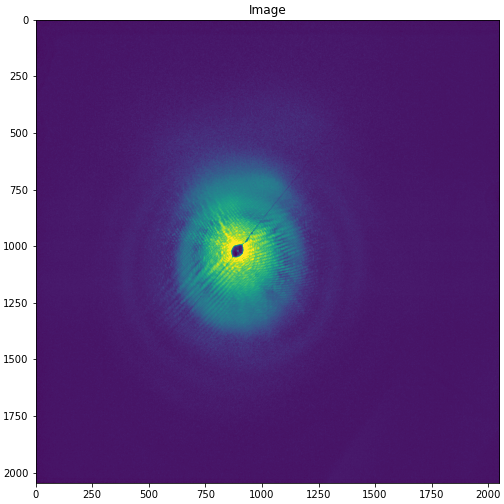

In [19]:
# Load image
if isinstance(im_id, list):
    images = np.stack([load_processing(idx)[0] for idx in im_id])
    image = np.mean(images, axis=0)
    print("list")
else:
    image, images = load_processing(im_id, file_indices=file_indices_im, crop=None)

# Plot
fig, ax = cimshow(helper.log_clip(image))
ax.set_title("Image")

## Load topo data set and average

  0%|          | 0/1 [00:00<?, ?it/s]

interactive(children=(FloatRangeSlider(value=(0.6020600199699402, 3.708793876171212), description='contrast', …

Text(0.5, 1.0, 'Topo')

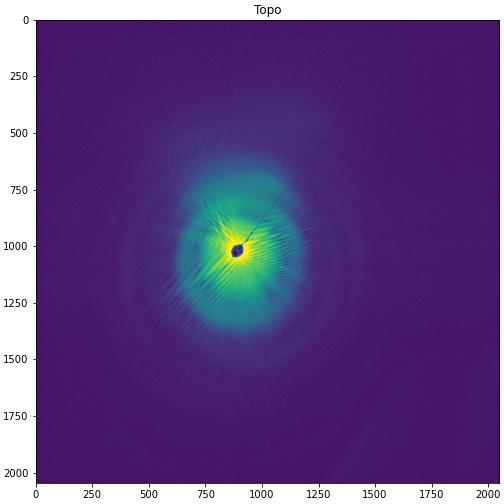

In [20]:
# Load topo
topo, _ = load_processing(topo_id, file_indices=None, crop=None)

# Plot
fig, ax = cimshow(helper.log_clip(topo))
ax.set_title("Topo")

## Load dark image

  0%|          | 0/1 [00:00<?, ?it/s]

interactive(children=(FloatRangeSlider(value=(92.76000213623047, 101.0), description='contrast', layout=Layout…

  0%|          | 0/1 [00:00<?, ?it/s]

interactive(children=(FloatRangeSlider(value=(92.76000213623047, 101.0), description='contrast', layout=Layout…

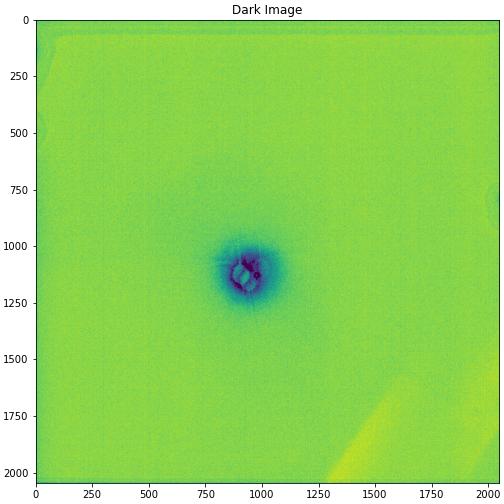

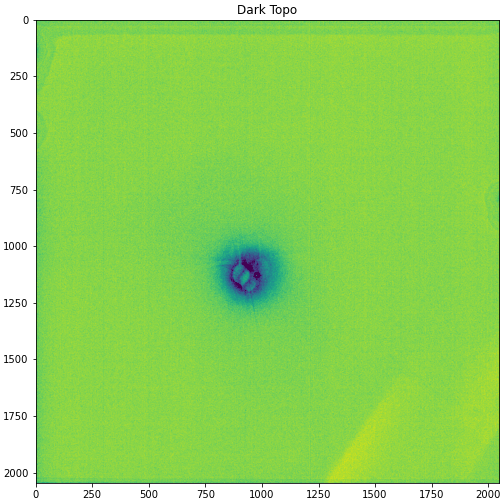

In [21]:
# Load image
if dark_id_im is not None:
    dark, _ = load_processing(dark_id_im, file_indices=None, crop=None)
    image = image - dark

    # Plot
    fig, ax = cimshow(dark)
    ax.set_title("Dark Image")

if dark_id_topo is not None:
    dark, _ = load_processing(dark_id_topo, crop=None)
    topo = topo - dark

    # Plot
    fig, ax = cimshow(dark)
    ax.set_title("Dark Topo")

# Center holograms

* Find center of the hologram to get a well-defined q-space. 
* Create smooth mask for beamstop or overexposed areas in direct beam

## Basic widget to find center

Try to **align** the circles to the **center of the scattering pattern**. Care! Position of beamstop might be misleading and not represent the actual center of the hologram. Circles are just a guide to eye and will not be used otherwise.

interactive(children=(FloatRangeSlider(value=(-0.9399948120117188, 4794.827427246657), description='contrast',…

interactive(children=(IntText(value=1055, description='c0 (vert)', step=0), IntText(value=903, description='c1…

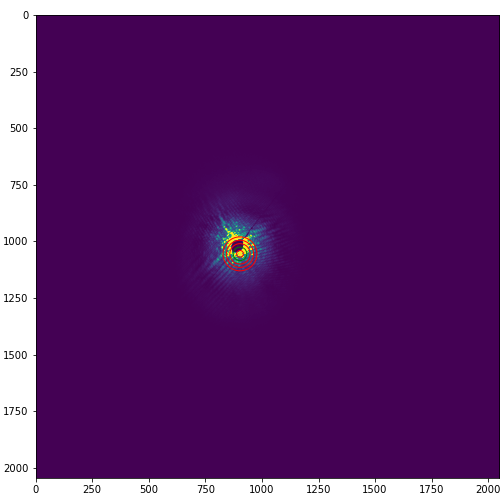

In [22]:
# Find center position via widget
c0, c1 = [1055, 903]  # initial values or [1026,894]
# c0, c1 = [496, 491]  # initial values
ic = interactive.InteractiveCenter(image, c0=c0, c1=c1)

In [23]:
# Get center positions
center = [ic.c0, ic.c1]

print(f"Center:", center)

Center: [1055, 903]


## Azimuthal integrator widget for finetuning
More of an "expert widget" which works very well for alignment if you have an Airy Pattern as a scattering image. PyFai transforms images from carthesian detector coordinate system into polar coordinate system with angle `phi` and radial distance `q` as axis (azimuthal transformation). The center of the coordinate system will be defined in the azimuthal integrator class and must not necessarily represents the center coordinates of your image array. If the center is set correctly, all rings of the Airy pattern will be transformed into a straight line in the I(q,chi)-plot as rings appear at a given q for all angles chi.

In [24]:
# Setup azimuthal integrator for virtual geometry
ai = AzimuthalIntegrator(
    dist=experimental_setup["ccd_dist"],
    detector=detector,
    wavelength=experimental_setup["lambda"],
    poni1=center[0]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # y (vertical)
    poni2=center[1]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # x (horizontal)
)

Text(0.5, 1.0, 'Azimuthal integration')

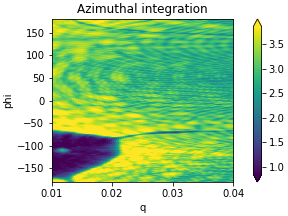

In [25]:
# Not the widget, just for double checking to find correct radial range for plotting
# Perform azimuthal transformation
I_t, q_t, phi_t = ai.integrate2d(
    np.log10(image - np.min(image) + 1),
    500,  # number of points for phi
    radial_range=(0.01, 0.04),  # relevant q-range
    unit="q_nm^-1",
    correctSolidAngle=False,
    method="BBox",
)
# Combine in an xarray for plotting
az2d = xr.DataArray(I_t, dims=("phi", "q"), coords={"q": q_t, "phi": phi_t})

# Plot
fig, ax = plt.subplots()
mi, ma = np.percentile(I_t, [1, 95])
az2d.plot.imshow(ax=ax, vmin=mi, vmax=ma)
plt.title(f"Azimuthal integration")

  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start
    self.asyncio_loop.run_forever()
  File "/asap3/petra3

Left: 1d azimuthal Integration I(q)
Right: 2d azimuthal Integration I(q,chi)
Use arrow buttons on keyboard to adjust center position after selecting a slider.
Try to transform all rings of the Airy pattern into a straight line in the 2d I(q,chi)-plot. Maximize fringe contrast in 1d I(q) plot for fine-tuning.


interactive(children=(FloatSlider(value=1055.0, description='y-center', layout=Layout(width='500px'), max=1365…

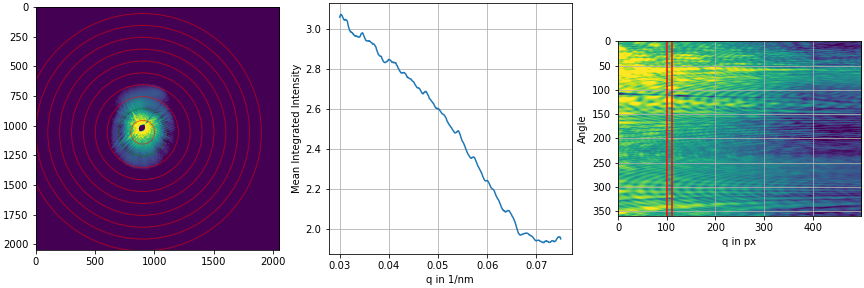

In [26]:
# The widget
aic = interactive.AzimuthalIntegrationCenter(
    helper.log_clip(image),
    # image,
    ai,
    c0=center[0],
    c1=center[1],
    im_data_range=[1, 98],
    radial_range=(0.03, 0.075),
    qlines=[100, 110],
)

In [ ]:
# Get center positions from widget
center = [aic.c0, aic.c1]
print(f"Center:", center)

## Here: Centering of image hologram

In [27]:
# Apply to topo and image
shift_c = np.array(image.shape) / 2 - center
im_c = cci.shift_image(image, shift_c)
topo_c = cci.shift_image(topo, shift_c)  # centered image

# Image Registration

Relative drift between data holograms and their corresponding topo holograms is calculated by image registration algorithm. Necessary to get well defined difference hologram. The reference is always the static background image (topo).

## Set Alignment ROI 

Set a region of interest (ROI) of reference (topo) use for image registration is performed. Can include beamstop when beamstop mask was defined.

How to use:
1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

interactive(children=(FloatRangeSlider(value=(-0.9400023221969604, 4794.8272792974385), description='contrast'…

Text(0.5, 1.0, "Don't include the beamstop as this will misdirect the algorithm")

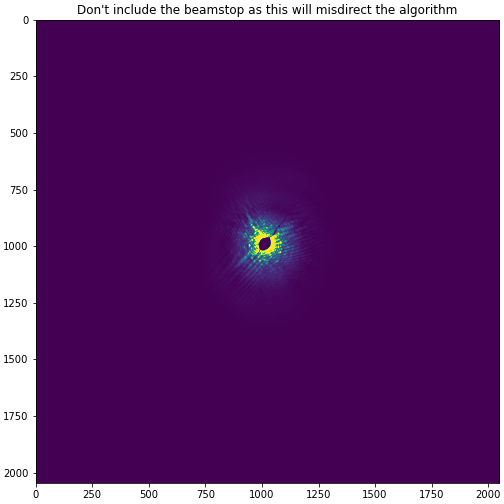

In [28]:
fig, ax = cimshow(im_c)
ax.set_title("Don't include the beamstop as this will misdirect the algorithm")

In [29]:
# Takes start and end of x and y axis
x1, x2 = ax.get_xlim()
y2, y1 = ax.get_ylim()
roi_im_reg = np.array([y1, y2, x1, x2]).astype(int)
# roi_im_reg  = [1031, 1189, 1117 ,1284]
roi_im_reg_s = np.s_[roi_im_reg[0] : roi_im_reg[1], roi_im_reg[2] : roi_im_reg[3]]

print(f"Image registration roi:", roi_im_reg)

Image registration roi: [ 772  957  911 1028]


## Calculate drift of images

In [32]:
shift = cci.image_registration(
    im_c[roi_im_reg_s],
    topo_c[roi_im_reg_s],
    method="dipy",
)
print("Relative shift is: %s" % shift)

Relative shift is: [-0.  0.]


No shift required
No shift required


Text(0.5, 1.0, 'Auto shift: [ 0. -0.]')

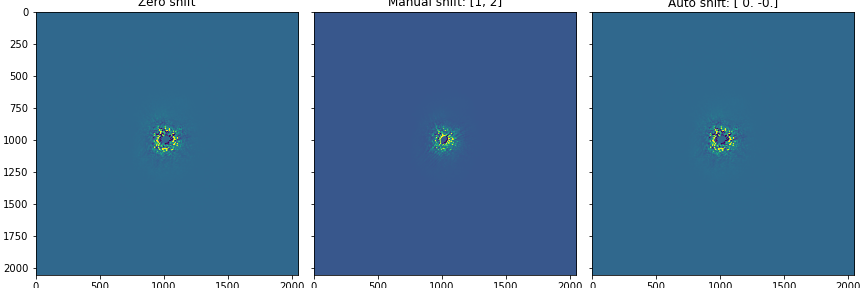

In [31]:
# Define shift manually for comparison
tmp_shift = [1, 2]

# Loop over shifts
temp_diff = np.zeros((3, im_c.shape[0], im_c.shape[1]))
shifts = [
    [0, 0],
    tmp_shift,
    -shift,
]
for i, tshift in enumerate(shifts):
    temp = cci.shift_image(im_c, tshift)
    temp_factor = cci.dyn_factor(temp, topo_c, method="correlation")
    temp_diff[i] = temp - temp_factor[0] * topo_c

# Plots for comparision
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(12, 4))
mi, ma = np.percentile(temp_diff[0], [0.1, 99.9])
ax[0].imshow(temp_diff[0], vmin=mi, vmax=ma)
ax[0].set_title("Zero shift")
mi, ma = np.percentile(temp_diff[1], [0.1, 99.9])
ax[1].imshow(temp_diff[1], vmin=mi, vmax=ma)
ax[1].set_title("Manual shift: %s" % shifts[1])
mi, ma = np.percentile(temp_diff[2], [0.1, 99.9])
ax[2].imshow(temp_diff[2], vmin=mi, vmax=ma)
ax[2].set_title("Auto shift: %s" % np.round(shifts[2], 2))

## Correct drift of topo

No shift required


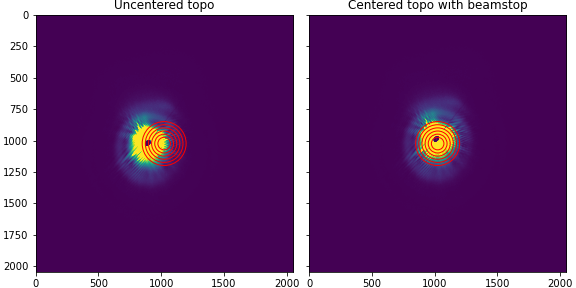

In [33]:
# Correct relative drift
topo_c = cci.shift_image(topo_c, shift)

# Plot original and shifted holos
mi, ma = np.percentile(np.real(topo_c[topo_c != 0]), (0.1, 99))
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
ax[0].imshow(np.real(topo), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Uncentered topo")
ax[1].imshow(np.real(topo_c), cmap="viridis", vmin=mi, vmax=ma)
ax[1].set_title("Centered topo with beamstop")

# Add circles with different radi r
tmp = np.array(image.shape) / 2
for r in np.arange(50, 200, 25):
    ax[0].add_artist(plt.Circle((tmp[1], tmp[0]), r, fill=None, ec="red"))
    ax[1].add_artist(plt.Circle((tmp[1], tmp[0]), r, fill=None, ec="red"))

# Create beamstops

We want to cover the beamstop with a smooth circle to cover its sharp edges as these would create ringing-like artifacts in the reconstruction plane. Make it only as large as necessary to keep as much information as possible.

## Manual masking of beamstop wires

Just mask the beamstop wires, broken pixels, etc. 

interactive(children=(FloatRangeSlider(value=(0.4857215216636658, 4.156882122945475), description='contrast', …

Click on the figure to create a polygon corner.
Click `Add mask` to store coordinates and apply mask.
Press the 'esc' key to reset the polygon for new drawing.

Try holding the 'shift' key to move all of the vertices.
Try holding the 'ctrl' key to move a single vertex.
Button `Delete mask` deletes the masks recursively.


Button(button_style='warning', description='Add mask', layout=Layout(height='auto', width='100px'), style=Butt…

Button(description='Delete mask', layout=Layout(height='auto', width='100px'), style=ButtonStyle())

Output()

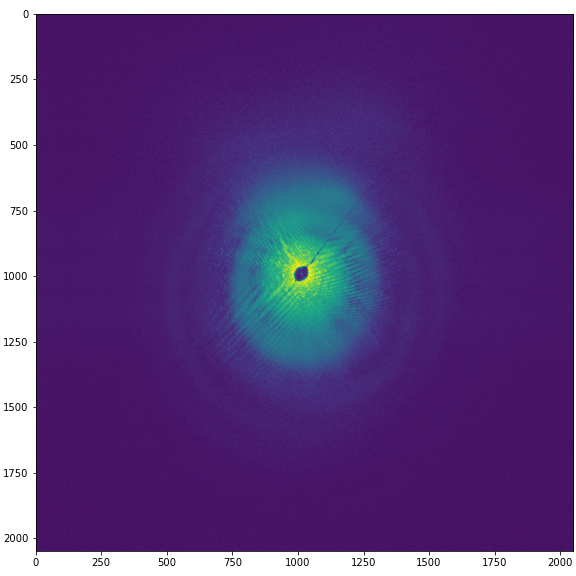

In [34]:
poly_mask = interactive.draw_polygon_mask(helper.log_clip(im_c))

Copy these coordinates into the 'load_poly_coordinates()' function:
[]


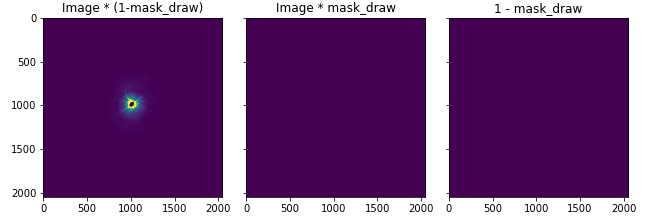

In [35]:
# Take poly coordinates and mask from widget
p_coord = poly_mask.get_vertice_coordinates()
mask_draw = poly_mask.full_mask.astype(int)

print("Copy these coordinates into the 'load_poly_coordinates()' function:")
print(p_coord)

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
mi, ma = np.percentile(im_c * (1 - mask_draw), [0.1, 99.9])
ax[0].imshow(im_c * (1 - mask_draw), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Image * (1-mask_draw)")

mi, ma = np.percentile(im_c * mask_draw, [0.1, 99.9])
ax[1].imshow(im_c * mask_draw, vmin=mi, vmax=ma)
ax[1].set_title("Image * mask_draw")

ax[2].imshow(1 - mask_draw)
ax[2].set_title("1 - mask_draw")
plt.tight_layout()

In [37]:
def load_poly_coordinates():
    """
    Dictionary that stores polygon corner coordinates of all drawn masks
    Example: How to add masks with name "test":
    mask_coordinates["test"] = copy coordinates from above
    """
    mask_coordinates = dict()
    mask_coordinates = dict()
    mask_coordinates["test"] = [[(1010.7, 964.7), (1004.3, 976.3), (988.1, 994.9), (981.1, 1016.9), (980.5, 1037.8), (989.2, 1054.1), (1004.9, 1065.1), (1019.4, 1076.7), (1027.5, 1082.5), (1043.8, 1066.3), (1052.5, 1052.9), (1063.5, 1039.0), (1063.5, 1022.2), (1060.0, 1004.2), (1050.7, 990.8), (1033.3, 976.3), (1025.2, 971.1), (1021.1, 964.7)]]
    mask_coordinates["epoxy_bs"] = [[(1053.4, 996.4), (1048.2, 988.8), (1042.6, 984.0), (1033.7, 978.3), (1028.1, 975.1), (1022.8, 973.6), (1022.4, 959.6), (1025.2, 957.3), (1025.4, 948.4), (1025.2, 939.4), (1022.9, 929.4), (1019.4, 922.1), (1012.3, 912.2), (1014.4, 910.0), (1014.4, 903.4), (1011.3, 892.9), (1016.8, 889.2), (1017.9, 886.0), (1010.5, 875.0), (1009.6, 873.2), (985.9, 663.4), (969.1, 535.8), (952.7, 379.3), (929.7, 224.2), (888.5, -5.7), (881.7, -5.7), (901.1, 94.5), (924.5, 226.7), (946.3, 382.0), (963.0, 551.6), (976.6, 666.6), (994.4, 822.5), (1000.5, 875.4), (997.3, 884.2), (999.3, 892.2), (1004.1, 894.2), (1006.5, 915.1), (1012.5, 956.3), (1013.3, 963.5), (1009.3, 970.7), (1009.3, 976.3), (1000.2, 983.7), (989.8, 995.3), (983.4, 1010.2), (982.2, 1028.6), (987.8, 1048.2), (1003.4, 1063.4), (1020.7, 1077.5), (1026.7, 1084.3), (1030.2, 1108.3), (1041.4, 1210.0), (1053.8, 1335.8), (1069.4, 1462.5), (1075.8, 1523.8), (1086.3, 1654.8), (1094.8, 1754.0), (1109.7, 1910.7), (1108.5, 1928.6), (1095.7, 2052.7), (1103.3, 2050.7), (1120.5, 1910.1), (1117.3, 1896.7), (1098.1, 1692.0), (1084.9, 1526.5), (1072.2, 1414.7), (1061.4, 1311.0), (1045.8, 1178.4), (1034.9, 1075.3), (1041.8, 1068.9), (1052.6, 1054.5), (1059.4, 1038.8), (1062.2, 1020.4), (1057.8, 1004.0)]]
    mask_coordinates["epoxy_crop"] = [[(495.4, 464.5), (476.4, 488.2), (475.5, 532.3), (503.3, 560.7), (515.0, 574.4), (515.0, 574.4), (520.3, 606.0), (545.8, 874.9), (560.6, 1011.4), (559.9, 1061.1), (584.8, 1030.9), (574.0, 938.6), (527.9, 574.5), (527.1, 560.2), (548.1, 536.5), (555.7, 507.2), (544.6, 479.4), (524.2, 466.1), (514.8, 460.4), (514.3, 443.2), (519.3, 432.1), (519.3, 432.1), (512.4, 404.0), (505.1, 383.4), (505.8, 370.6), (502.0, 356.6), (486.1, 231.7), (462.6, -8.5), (442.8, -7.6), (468.8, 235.4), (482.3, 321.7), (494.9, 411.3)]]
    mask_coordinates["cross"] = [[(897.0, 245.1), (851.2, -19.0), (803.8, -16.3), (853.8, 249.8), (987.8, 962.0), (980.6, 980.8), (965.6, 1000.7), (922.5, 1015.6), (802.6, 1034.9), (-60.9, 1213.5), (-48.8, 1263.3), (205.0, 1207.4), (961.6, 1046.0), (971.9, 1048.7), (991.0, 1062.2), (998.9, 1064.6), (1005.1, 1069.3), (1014.5, 1115.5), (1189.7, 2068.9), (1254.1, 2058.6), (1208.9, 1943.4), (1062.6, 1148.6), (1048.8, 1081.3), (1049.7, 1059.8), (1071.2, 1031.7), (1069.8, 998.1), (1059.4, 984.1), (1027.3, 961.7)]]
    mask_coordinates["cross_full"] = [[(-11.9, 1125.8), (92.4, 1148.7), (900.2, 1005.1), (928.5, 946.5), (991.9, 897.3), (918.6, 338.4), (854.3, -16.8), (906.2, -29.7), (960.4, 333.4), (1031.0, 845.4), (1042.4, 869.0), (1029.6, 883.8), (1042.4, 897.3), (1090.3, 914.1), (1124.0, 957.9), (1138.8, 976.1), (1574.7, 929.1), (2059.8, 853.1), (2053.8, 900.0), (1589.1, 972.6), (1144.2, 1028.0), (1121.8, 1085.5), (1059.3, 1126.5), (1061.4, 1176.1), (1152.5, 1849.3), (1164.5, 1914.0), (1132.2, 2060.6), (1093.8, 2068.1), (1108.0, 1928.2), (1111.9, 1874.9), (1014.7, 1167.9), (1010.8, 1131.9), (972.3, 1116.4), (932.6, 1088.7), (900.9, 1045.6), (86.4, 1195.7), (-14.4, 1169.7)]]
    mask_coordinates["dust"] = [[(1078.9, 1028.9), (1075.5, 1032.3), (1075.6, 1035.2), (1077.4, 1037.4), (1083.6, 1037.1), (1085.8, 1036.1), (1084.9, 1030.2)]]
    mask_coordinates["epoxy_short"]= [[(862.8, -5.1), (905.7, 235.4), (923.5, 325.8), (949.7, 453.7), (975.8, 675.6), (1002.8, 911.5), (1008.8, 945.2), (1012.7, 964.3), (1012.1, 986.1), (994.3, 1012.4), (993.0, 1042.7), (1006.1, 1055.2), (1023.3, 1063.8), (1029.9, 1115.3), (1055.5, 1358.0), (1113.1, 1972.4), (1114.0, 2096.1), (1132.2, 2096.1), (1127.9, 1970.5), (1118.3, 1853.5), (1075.3, 1354.0), (1039.4, 1062.7), (1049.8, 1046.2), (1057.6, 1022.8), (1048.1, 999.5), (1031.6, 985.6), (1029.9, 970.0), (1033.4, 957.9), (1023.9, 936.2), (993.7, 676.7), (963.4, 449.8), (919.6, 177.8), (880.2, -13.5)]]
    mask_coordinates["cross_close"]= [[(836.9, -9.5), (911.8, 314.3), (946.1, 537.0), (968.5, 672.2), (996.6, 870.8), (1003.2, 940.4), (980.9, 956.4), (962.3, 975.4), (948.4, 995.9), (938.9, 1025.5), (467.5, 1105.7), (84.3, 1170.1), (7.4, 1155.0), (-12.5, 1166.2), (-13.7, 1191.8), (88.0, 1210.3), (394.0, 1155.3), (912.0, 1058.0), (940.2, 1052.4), (961.9, 1082.9), (987.3, 1105.1), (1013.9, 1113.9), (1035.6, 1270.3), (1089.0, 1647.2), (1147.5, 1969.2), (1178.5, 2076.5), (1213.6, 2072.3), (1184.4, 1953.1), (1054.9, 1159.8), (1052.0, 1119.7), (1059.3, 1107.4), (1090.0, 1083.7), (1110.8, 1039.4), (1148.3, 1029.7), (1198.9, 1028.8), (1574.3, 982.0), (1931.9, 916.8), (2067.4, 893.7), (2061.5, 854.8), (1690.4, 925.0), (1327.6, 978.4), (1107.3, 1005.2), (1097.2, 983.1), (1078.4, 960.2), (1054.2, 947.5), (1029.4, 942.8), (1027.4, 932.7), (1036.1, 926.0), (1033.4, 915.3), (1026.0, 913.2), (1007.9, 752.1), (952.0, 346.6), (879.8, -16.7)], [(-13.6, 438.4), (748.0, -9.0), (-41.4, -21.8)]]
    mask_coordinates["burn"] = [[(1043.3, 1078.9), (1033.3, 1087.9), (1027.2, 1099.6), (1036.0, 1106.5), (1040.1, 1113.0), (1048.5, 1119.6), (1055.8, 1114.5), (1066.3, 1109.2), (1068.7, 1103.0), (1068.8, 1098.1), (1066.6, 1089.2), (1062.7, 1084.3), (1058.7, 1081.5), (1056.1, 1078.9), (1052.4, 1077.6), (1048.4, 1077.3), (1044.6, 1077.4)]]
    mask_coordinates["epoxy_short2"]= [[(997.7, 1046.1), (994.1, 1021.6), (1002.0, 998.8), (1016.1, 991.6), (1037.4, 989.1), (1052.5, 1000.3), (1056.9, 1014.7), (1048.2, 1044.3), (1037.4, 1052.6), (1014.6, 1056.6), (1004.2, 1054.4)], [(1032.0, 996.8), (1054.5, 979.9), (1121.9, 890.0), (1374.8, 561.2), (1782.2, -16.2), (1804.7, -13.4), (1492.8, 439.0), (1303.1, 690.5), (1199.2, 816.9), (1086.8, 958.8), (1067.1, 985.5), (1037.6, 1010.8)], [(231.4, 2053.8), (193.9, 2051.1), (429.8, 1724.0), (774.3, 1323.1), (966.0, 1089.9), (1008.9, 1038.9), (1017.0, 1045.6), (972.7, 1101.9), (778.4, 1343.2), (449.9, 1744.1)], [(1843.7, 1542.6), (1885.5, 1532.4), (2069.7, 1675.9), (2061.5, 1712.8), (1844.6, 1555.8)]]
    
    return mask_coordinates

Text(0.5, 1.0, '1 - mask_draw')

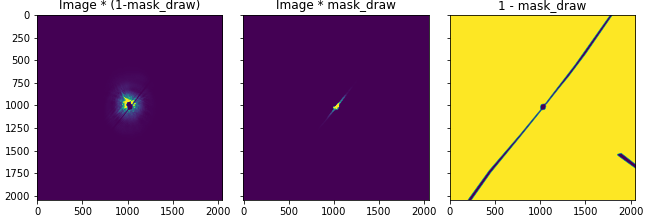

In [38]:
# Which drawn masks do you want to load? You can combine multiple masks from
# load_poly_coordinates(). Just add names of mask as strings to list like
# ["bs_small","bs_medium"]
polygon_names = ["epoxy_short2"]  # ["epoxy_bs"] ["bs_test"]
mask_draw = mask_lib.load_poly_masks(
    image.shape,
    load_poly_coordinates(),
    polygon_names,
)

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
mi, ma = np.percentile(im_c * (1 - mask_draw), [0.1, 99.9])
ax[0].imshow(im_c * (1 - mask_draw), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Image * (1-mask_draw)")

# mi, ma = np.percentile(im_c * mask_draw, [0.1, 90])
ax[1].imshow(im_c * mask_draw, vmin=mi, vmax=ma)
ax[1].set_title("Image * mask_draw")

ax[2].imshow(1 - mask_draw)
ax[2].set_title("1 - mask_draw")

## Finetuning of mask position

interactive(children=(FloatRangeSlider(value=(-0.9400023221969604, 4794.8272792974385), description='contrast'…

interactive(children=(FloatSlider(value=0.0, description='shift_ver', layout=Layout(width='350px'), max=1024.0…

FloatSlider(value=0.0, step=0.0005)

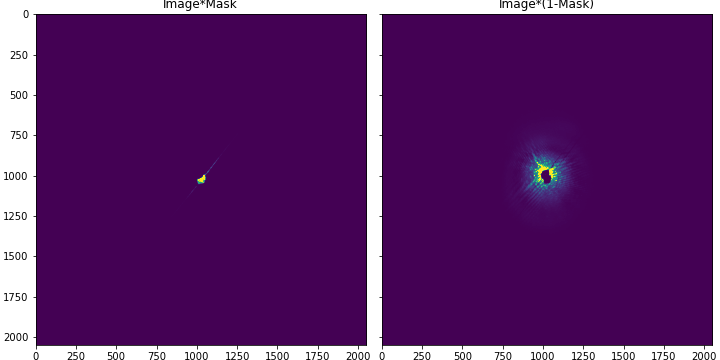

In [44]:
# Use widget to shift and expand or shrink the mask
ss_mask = interactive.Shift_Scale_Mask(im_c, mask_draw, shift=[0, -1], scale=-3)
ipywidgets.FloatSlider(step=0.0005)

In [40]:
# Take mask, shift and scaling from widget
mask_draw, mask_shift, mask_scale = ss_mask.get_mask()

## Overview beamstops
Verify good beamstop alignment

Text(0.5, 1.0, 'Image-Topo')

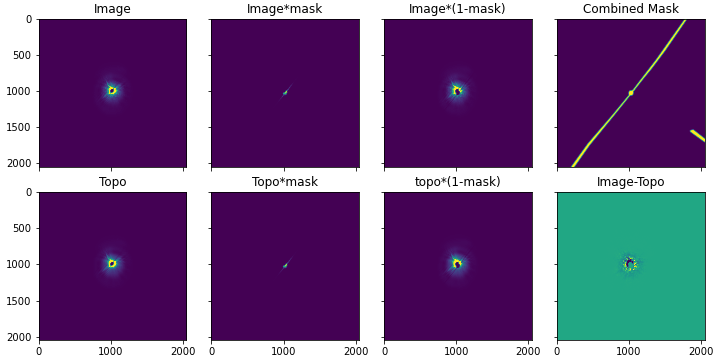

In [41]:
# Smoothing of beamstop mask
bs_smoothing = 2

# Add circular beamstop mask
mask_im = mask_draw.copy()
mask_topo = mask_draw.copy()

# Mask over-saturated pixel
mask_im = mask_im + (im_c > experimental_setup["oversaturation"])
mask_topo = mask_topo + (topo_c > experimental_setup["oversaturation"])

# Combine both
mask_pixel = mask_im + mask_topo
mask_pixel[mask_pixel > 1] = 1

# Create smooth mask for FTH reconstructions
footprint = skimage.morphology.disk(3 * bs_smoothing)
mask_pixel_smooth = skimage.morphology.dilation(mask_pixel, footprint)
mask_pixel_smooth = gaussian_filter(mask_pixel_smooth, bs_smoothing)

# Plot both
fig, ax = plt.subplots(2, 4, figsize=(10, 5), sharex=True, sharey=True)
mi, ma = np.percentile(im_c, [1, 99.9])
ax[0, 0].imshow(im_c, vmin=mi, vmax=ma)
ax[0, 0].set_title("Image")
mi, ma = np.percentile(im_c * mask_im, [1, 99.99])
ax[0, 1].imshow(im_c * mask_im, vmin=mi, vmax=ma)
ax[0, 1].set_title("Image*mask")
mi, ma = np.percentile(im_c * (1 - mask_im), [0.1, 99.9])
ax[0, 2].imshow(im_c * (1 - mask_im), vmin=mi, vmax=ma)
ax[0, 2].set_title("Image*(1-mask)")
ax[0, 3].imshow(mask_pixel_smooth)
ax[0, 3].set_title("Combined Mask")

mi, ma = np.percentile(topo_c, [1, 99.9])
ax[1, 0].imshow(topo_c, vmin=mi, vmax=ma)
ax[1, 0].set_title("Topo")
mi, ma = np.percentile(topo_c * mask_im, [1, 99.99])
ax[1, 1].imshow(topo_c * mask_topo, vmin=mi, vmax=ma)
ax[1, 1].set_title("Topo*mask")
mi, ma = np.percentile(topo_c * (1 - mask_topo), [0.1, 99.9])
ax[1, 2].imshow(topo_c * (1 - mask_topo), vmin=mi, vmax=ma)
ax[1, 2].set_title("topo*(1-mask)")
mi, ma = np.percentile((im_c - topo_c) * (1 - mask_pixel_smooth), [0.1, 99.9])
ax[1, 3].imshow((im_c - topo_c) * (1 - mask_pixel_smooth), vmin=mi, vmax=ma)
ax[1, 3].set_title("Image-Topo")

# Here: Calculate difference holograms

You can see the reconstrution of the magnetization only after subtracting the large background that you get from the diffraction on the circular object aperture (Airy Pattern). This might require a scaling factor to correct intensity changes between the hologram and the topo. Scaling factor will be determined automatically by a linear fit. If the fit seems off, there might be an issue with the data

In [ ]:
# Get scaling factor and offset
factor, offset = cci.dyn_factor(
    im_c * (1 - mask_pixel),
    topo_c * (1 - mask_pixel),
    method="correlation",
    verbose=True,
    plot=True,
)
# factor = 1
# offset = 0
# Calculate differences (magnetic) and sums (topographc) contrast holograms.
# _c: centered, without beamstop, _b: centered, with beamstop
diff_c = im_c / factor - topo_c - offset
sum_c = im_c / factor + topo_c - offset

In [ ]:
# Plot an example of the difference or sum hologram
tmp = diff_c * (1 - mask_pixel_smooth)
# fig, ax = cimshow(np.sign(tmp) * helper.log_clip(np.abs(tmp)))
fig, ax = cimshow(tmp, cmap="coolwarm")
ax.set_title(f" Diff Id %s - %s" % (im_id, topo_id))

# fig, ax = cimshow(sum_b)
# ax.set_title(f" Sum Id %d" % im_id)

# Reconstruct Diff Holos (FTH)

Reconstruct the hologram.

0. If you are doing heraldo, determine the rotation angle of the hologram
1. Choose a region of interest (ROI) which means selecting one reconstruction from the reconstruction plane.
2. Propagate the image and shift the phase for maximal contrast and sharpness in your ROI

## Set Patterson Map ROI

Choose the reconstructions as the ROI.

1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

In [ ]:
# Choose contrast mode
# diff_c: magnetic contrast only
# sum_c: topographic contrast only
holo = diff_c * (1 - mask_pixel_smooth)
# holo = sum_c * (1 - mask_pixel_smooth)

tmp = fth.reconstruct(holo)

fig, ax = cimshow(np.real(tmp), cmap="gray")

In [ ]:
# Execute to get roi
x1, x2 = ax.get_xlim()
y2, y1 = ax.get_ylim()
roi = np.array([y1, y2, x1, x2]).astype(int)  # ystart, ystop, xstart, xstop
# roi = [784, 942, 758, 908]
roi_s = np.s_[roi[0] : roi[1], roi[2] : roi[3]]
print(f"Roi Reco:{roi}")

## Tune propagation and phase
Focus the image by tuning the propagation distance. This really works like focussing in a microscope.
Phase slider will move contrast between real and imaginary part. Usually we use the phase which maximizes the contrast in the real part.

In [ ]:
# Widget
holo = sum_c * (1 - mask_pixel_smooth)
holo = diff_c * (1 - mask_pixel_smooth)

slider_prop, slider_phase, button = reco.propagate(
    holo,
    roi_s,
    phase=0,  # Initial value
    prop_dist=-0,  # Initial value
    experimental_setup=experimental_setup,
    scale=(0.1, 99.9),
)

In [ ]:
# Read prop dist and phase from widget
prop_dist = slider_prop.value
phase = slider_phase.value

print(f"Propagation distance: %0.2f" % prop_dist)
print(f"Phase: %0.2f" % phase)

## Save reconstruction

Save png files of the images and a h5 file containing all important variables

In [ ]:
# Style of reconstruction plot
def plot_recon(recon, title, rvmin=1, rvmax=99):
    # Plot
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(title)

    vmin, vmax = np.percentile(np.real(recon), (rvmin, rvmax))
    t_im1 = ax[0].imshow(np.real(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[0].set_title("Real")
    plt.colorbar(t_im1, ax=ax[0], aspect=50)

    vmin, vmax = np.percentile(np.imag(recon), (1, 99))
    t_im2 = ax[1].imshow(np.imag(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[1].set_title("Imag")
    plt.colorbar(t_im2, ax=ax[1], aspect=50)

In [ ]:
def get_title(
    data_key, im_id, topo_id, CDI=False, Framenumber=None
):  # needs to be updated
    # Rotation in title
    if data_key is not None:
        data = load_key(im_id, mnemonics[data_key])

    if CDI is False:
        mode = "FTH"
    elif CDI is True:
        mode = "CDI"

    if data_key == "magnet_mT":
        if Framenumber != None:
            title = "Image %s - %s %s: @ %.2f mA " % (
                im_id,
                topo_id,
                mode,
                data[Framenumber] * 1000,
            )
        else:
            print(data)
            title = "Image %s - %s %s: @ %.2f mA " % (
                im_id,
                topo_id,
                mode,
                data * 1000,
            )

    elif data_key == "energy":
        title = "Image %s - %s %s: %s = %.2f " % (
            im_id,
            topo_id,
            mode,
            data_key,
            data,
        )
    elif data_key == "magnet_A":
        if Framenumber is not None:
            title = "Image %s - %s %s @ %.2f A, %.2f K " % (
                im_id,
                topo_id,
                mode,
                load_key(im_id, mnemonics["magnet_A"])[Framenumber],
                load_key(im_id, mnemonics["cryo"])[Framenumber],
            )
        else:
            title = "Image %s - %s %s @ %.2f A, %.2f K " % (
                im_id,
                topo_id,
                mode,
                load_key(im_id, mnemonics["magnet_A"]),
                load_key(im_id, mnemonics["cryo"]),
            )
    else:
        title = "Image %s - %s %s " % (
            im_id,
            topo_id,
            mode,
        )
    if Framenumber != None:
        title += f"Frame: {Framenumber}"

    return title

In [ ]:
# Create plot
holo = diff_c * (1 - mask_pixel_smooth)

# Reconstruct
recon = fth.reconstruct(
    fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
    * np.exp(1j * phase)
)

# Create plot
title = get_title(None, im_id, topo_id)
plot_recon(recon[roi_s], title)

# Save images
fname = join(
    folder_general,
    "Recon_ImId_%s_RefId_%s_%s.png" % (im_id, topo_id, USER),
)
print("Saving: %s" % fname)
plt.savefig(fname, bbox_inches="tight", transparent=False)

# Save hdf5 file
save_fth_h5()

In [ ]:
# Closes all existing plots
plt.close("all")

# Batch processing FTH (update!)

# CDI Reconstruction

## Create set of pos and neg helicity holograms

CDI algorithm needs holograms recorded wih both helicity ($\sigma = \pm 1$) as input. We use will calculate those from our previously centered and intensity normalized holograms according to;´; 

$Image(\sigma) = Topo + \sigma \cdot diff $,

In [ ]:
# Choose either option
pos = (sum_c + diff_c) / 2
neg = (sum_c - diff_c) / 2

pos = im_c / factor
neg = topo_c.copy()

## Create Support mask
The support mask is the real-space constraint used for the (holographically-aided) phase retrieval, i.e., certain details about our sample like the sample geometry. For our samples we can directly derive a very strong constraint: The FTH reconstructions show us previsely the actual real-space sample structure, i.e., the arrangement of our aperture where x-rays are transmitted ("1") while the masked areas show no transmission ("0"). We will therefore create a binary mask that reflects this transmission as an input for the phase retrieval.

How to draw a support mask: Create a binary mask of the locations of sample apertures in the fth reconstruction. Areas with apertures are "1". Select only a single set of reconstructions (object & reference apertures) that originate from a single reference. Use the widget!

### Option 1: Execute if you want to create a new support mask
If you really want to create a new support mask, execute next cell and then the "InteractiveCircleCoordinates"-widget

In [ ]:
# How many references do you have?
nr_ref = 3

# Setup coordinates (nr_ref + 1 coordinates, as there is always the object aperture)
support_coordinates = [
    [pos.shape[-2] // 2, pos.shape[-1] // 2, 7] for k in range(nr_ref + 1)
]

# Widget to find the positions and sizes of the different apertures
print(
    "Cover the object & reference apertures for each set of reconstructions that originates from the same reference with circles."
)
print(
    "Optimization: Change one circle parameter, calc phase retrieval image, compare with images reconstructed with old circle parameter. Repeat!"
)

# Create plot
holo = pos * (1 - mask_pixel_smooth)

# Reconstruct
recon = fth.reconstruct(
    fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
    * np.exp(1j * phase)
)
recon = np.real(recon)

ds = interactive.InteractiveCircleCoordinates(
    recon,
    len(support_coordinates),
    coordinates=support_coordinates.copy(),
)

In [ ]:
# Take coordinates of circles from widget
support_coordinates = ds.get_params()

# Create supportmask from coordinates
supportmask = mask_lib.create_circle_supportmask(support_coordinates, pos.shape)

# Plot supportmask as overlay
fig, ax = plt.subplots(figsize=(6, 6))
mi, ma = np.percentile(recon, (1, 99))
ax.imshow(recon, vmin=mi, vmax=ma, cmap="gray")
ax.imshow(supportmask, alpha=0.4, cmap="binary")
ax.set_title("Image with overlayed mask")

### Option 2: Execute if you want to load an existing support mask created with circle mask widget

In [ ]:
def get_supportmask_coordinates(sample):
    """
    Dictionary that stores coordinates of circular support mask apertures
    """

    # Setup dictonary
    support_coord = dict()

    # coordinates
    support_coord["s2402_D1"] = [
        (969.5, 726.0, 77.0),
        (1103.0, 457.0, 7.0),
        (1269.5, 769.5, 7.0),
        (705.5, 868.0, 7.0),
        (755.3, 518.0, 7.0),
        (1024.0, 1024.0, 7.0),
    ]
    support_coord["s2402_D1_new"] = [
        (976.5, 726.0, 77.0),
        (1118.0, 460.5, 7.0),
        (1276.0, 776.5, 7.0),
        (710.0, 860.5, 7.0),
        (768.0, 512.0, 7.0),
        (1024.0, 1024.0, 7.0),
    ]
    support_coord["s2402_D1_cropped"] = [
        (405.5, 408.0, 39.0),
        (377.5, 259.0, 4.0),
        (537.0, 337.0, 4.0),
        (254.5, 386.0, 5.0),
        (337.5, 542.0, 4.0),
        (512.0, 512.0, 4.0),
    ]
    support_coord["CoPd_cropped"] = [
        (465.0, 412.0, 30.0),
        (485.5, 303.7, 5.0),
        (574.5, 398.0, 5.0),
        (367.5, 360.0, 5.0),
        (384.5, 488.0, 5.0),
        (512.0, 512.0, 5.0),
    ]
    support_coord["s2507_B3"] = [
        (931.0, 822.0, 60.5),
        (970.5, 607.0, 8.0),
        (1148.5, 796.0, 8.0),
        (735.0, 717.5, 8.0),
        (769.0, 976.0, 8.0),
        (1024.0, 1024.0, 8.0),
    ]
    support_coord["RT_FGT"] = [
        (885.0, 678.5, 113.5),
        (600.5, 919.0, 8.5),
        (796.0, 1040.5, 8.5),
        (1024.0, 1024.0, 8.5),
    ]
    support_coord["RT_FGT_1024px"] = [
        (885.0 / 2, 678.5 / 2, 113.5 / 2),
        (600.5 / 2, 919.0 / 2, 8.5 / 2),
        (796.0 / 2, 1040.5 / 2, 8.5 / 2),
        (1024.0 / 2, 1024.0 / 2, 8.5 / 2),
    ]
    return support_coord[sample]

In [ ]:
# Which supportmask to load? ("s2306a-C1", "s2308a-B1", ...)
sample = "RT_FGT"

# Get coordinates and create supportmask
support_coordinates = get_supportmask_coordinates(sample)

In [ ]:
# Widget to find the positions and sizes of the different apertures
print(
    "Cover the object & reference apertures for each set of reconstructions that originates from the same reference with circles."
)
print(
    "Optimization: Change one circle parameter, calc phase retrieval image, compare with images reconstructed with old circle parameter. Repeat!"
)

# Create plot
holo = pos * (1 - mask_pixel_smooth)
ds = interactive.InteractiveCircleCoordinates(
    np.real(fth.reconstruct(holo)),
    len(support_coordinates),
    coordinates=support_coordinates,
)

In [ ]:
# Take coordinates of circles from widget
support_coordinates = ds.get_params()

# Create supportmask
supportmask = mask_lib.create_circle_supportmask(support_coordinates, pos.shape)

# What to plot?
tmp = np.real(fth.reconstruct(holo))

# Plot supportmask as overlay
fig, ax = plt.subplots(figsize=(6, 6))
mi, ma = np.percentile(tmp, (1, 99))
ax.imshow(tmp, vmin=mi, vmax=ma, cmap="gray")
ax.imshow(supportmask, alpha=0.3, cmap="binary")
ax.set_title("Image with overlayed mask")

### Take Roi
Choose the reconstructions as the ROI.

1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

In [ ]:
fig, ax = cimshow(supportmask.astype(int))

In [ ]:
# x1, x2 = ax.get_xlim()
# y2, y1 = ax.get_ylim()
# roi_cdi = np.array([int(x1), int(x2), int(y1), int(y2)])  # xstart, xstop, ystart, ystop
roi_cdi = [127, 227, 217, 323]
roi_cdi_s = np.s_[roi_cdi[0] : roi_cdi[1], roi_cdi[2] : roi_cdi[3]]

print(roi_cdi_s)

## Do Phase Retrieval

In [ ]:
# Executes the algorithm
offset_vmin = 0.75
# recon = fth.reconstruct(
#    fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
#    * np.exp(1j * phase)
# )
# Startimage = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(supportmask * recon)))
Startimage = None
Startgamma = None

(
    retrieved_p,
    retrieved_n,
    retrieved_p_pc,
    retrieved_n_pc,
    bsmask_p,
    bsmask_n,
    gamma_p,
    gamma_n,
) = phase_retrieval(
    pos,
    neg,
    mask_pixel,
    supportmask,
    vmin=offset_vmin,
    Startimage=Startimage,
    Startgamma=Startgamma,
)

## Reconstruct images from phase retrieval

In [ ]:
# New beamstop for CDI recos as phase retrieval of low-q might be insufficient. If phase retrieval worked well
# Try without beamstop: `use_bs = False`
use_bs = False
bs_diam_cdi = 25  # diameter of beamstop


# Create beamstop
if use_bs is True:
    mask_bs_cdi = 1 - mask_lib.circle_mask(
        topo.shape, np.array(topo.shape) / 2, bs_diam_cdi, sigma=4
    )
    mask_bs_cdi = 1 - mask_pixel_smooth.copy()
elif use_bs is False:
    mask_bs_cdi = np.ones(pos.shape)  # if you don't want a beamstop

# Get Recos partial coherence
# Positiv partial coherence
p_pc = cci.reconstruct(
    fth.propagate(
        retrieved_p_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)

# Negative partial coherence
n_pc = cci.reconstruct(
    fth.propagate(
        retrieved_n_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)

# Plotting
mode = "-"
print("Fine-tuning of reconstruction parameter:")
slider_prop, slider_phase, slider_dx, slider_dy = rec.focusCDI(
    retrieved_p_pc * mask_bs_cdi,
    retrieved_n_pc * mask_bs_cdi,
    roi_cdi_s,
    mask=supportmask,
    phase=phase_cdi,
    dx=dx,
    dy=dy,
    prop_dist=prop_dist_cdi,
    experimental_setup=experimental_setup,
    operation=mode,
    max_prop_dist=3,
    scale=(2, 98),
)

In [ ]:
# Get phase from slider
phase_cdi = slider_phase.value
prop_dist_cdi = slider_prop.value

# Reconstruct images with new parameter
p_pc = fth.reconstructCDI(
    fth.propagate(
        retrieved_p_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
) * np.exp(1j * phase_cdi)

n_pc = fth.reconstructCDI(
    fth.propagate(
        retrieved_n_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
) * np.exp(1j * phase_cdi)


print("Phase CDI: %s" % phase_cdi)
print("Prop_dist: %s" % prop_dist_cdi)

In [ ]:
# Confirm that offset subtraction in cdi function works, i.e., only small fraction of hologram is actually masked
fig, ax = plt.subplots(2, 2, figsize=(8, 8), sharex=True, sharey=True)
tmp = np.abs(retrieved_p_pc * mask_bs_cdi)
mi, ma = np.percentile(tmp, [0.1, 99.9])
ax[0, 0].imshow(tmp, vmin=mi, vmax=ma)
ax[0, 0].set_title("Pos holo")

tmp = np.abs(retrieved_n_pc)
mi, ma = np.percentile(tmp, [0.1, 99.9])
ax[0, 1].imshow(tmp, vmin=mi, vmax=ma)
ax[0, 1].set_title("Neg holo")
ax[1, 0].imshow(bsmask_p)
ax[1, 0].set_title("Pos holo mask")
ax[1, 1].imshow(bsmask_n)
ax[1, 1].set_title("Neg holo mask")

In [ ]:
# cimshow(helper.log_clip(np.abs(retrieved_n_pc)))
cimshow(np.log(np.abs(retrieved_n_pc)))

## Save reconstructions

In [ ]:
def plot_recon(recon, title, scale_mask=None):
    if scale_mask is None:
        scale_mask = np.ones(recon.shape)

    # Plot
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(title)

    tmp = np.real(recon) * scale_mask
    vmin, vmax = np.nanpercentile(tmp[tmp != 0], (1, 99))
    t_im1 = ax[0].imshow(np.real(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[0].set_title("Real")
    plt.colorbar(t_im1, ax=ax[0], aspect=50)

    tmp = np.imag(recon) * scale_mask
    vmin, vmax = np.nanpercentile(tmp[tmp != 0], (1, 99))
    t_im2 = ax[1].imshow(np.imag(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[1].set_title("Imag")
    plt.colorbar(t_im2, ax=ax[1], aspect=50)

In [ ]:
# Saves only real and imaginary part
recon = p_pc - n_pc
# recon = (p_pc - n_pc)  / (p_pc + n_pc)
# recon = np.log(p_pc) - np.log(n_pc)

# footprint = skimage.morphology.disk(4)
shrink_mask = skimage.morphology.erosion(supportmask, footprint)

# Plot
title = get_title(None, im_id, topo_id, CDI=True)
plot_recon(
    recon[roi_cdi_s] * supportmask[roi_cdi_s],
    title,  # scale_mask=shrink_mask[roi_cdi_s]
)

# Save images
fname = join(
    folder_general,
    "Recon_ImId_%s_RefId_%s_cdi_diff_%s.png" % (im_id, topo_id, USER),
)
print("Saving: %s" % fname)
plt.savefig(fname, bbox_inches="tight", transparent=False)

# Save h5
save_cdi_h5()

# Batch processing CDI

## Define Scan Ids

In [ ]:
# Load support mask of which sample?
energy_mode = "s2402_D1_cropped"
support_coordinates = get_supportmask_coordinates(sample)

In [ ]:
# Define the sets for reconstructions. You can make a list or use np.arange
# im_id_set should always have ids of positive helicity holograms,
# topo_id_set those of negative helicity or a hologram of a saturated state

# You can also use nested lists:
# in case topo_id_set = [[id1,id2],id3 it will use the sum hologram
# calculated from [id1,id2] as topo


im_id_set = [2237, 2238]  # np.arange(873,879)
topo_id_set = [2235] * len(im_id_set)

use_sub_frame = True

im_frames = None  # np.arange(0,len(im_id_set)) which stacks to load for image dataset
topo_frames = [0]  # which stack to load from toposet

dark_id_im_set = [2236] * np.ones(len(im_id_set), dtype=int)

# In case of single helicity reconstructions, adapt the helicity
helicity = [1] * len(im_id_set)

print("Dynamics Set:  %s" % im_id_set)
print("Reference Set: %s" % topo_id_set)
print("Image index Set: %s" % im_frames)

## Execute Phase Retrieval

## Stack in single im_ids

In [ ]:
# Define the sets for reconstructions. You can make a list or use np.arange
# im_id_set should always have ids of positive helicity holograms,
# topo_id_set those of negative helicity or a hologram of a saturated state

# You can also use nested lists:
# in case topo_id_set = [[id1,id2],id3 it will use the sum hologram
# calculated from [id1,id2] as topo


im_id_set = [2267]  # np.arange(873,879)#[869]  # [896]
topo_id_set = [2268] * len(im_id_set)  # [893]
# * np.ones(len(im_id_set), dtype=int)  # [[892]]

use_sub_frame = True

im_frames = None  # [0]#[-1] #np.arange(0,len(im_id_set))
topo_frames = [0]

dark_id_im_set = [2265] * np.ones(len(im_id_set), dtype=int)
# In case of single helicity reconstructions, adapt the helicity
helicity = [1] * len(im_id_set)

print("Dynamics Set:  %s" % im_id_set)
print("Reference Set: %s" % topo_id_set)
print("Image index Set: %s" % im_frames)

In [ ]:
dark_all, _ = load_processing(dark_id_im_set[0], file_indices=None)
if isinstance(topo_id_set[0], list):
    print("Using Topo from sum of two helicity holograms")

    topo = (
        load_processing(topo_id_set[0][0])[0] + load_processing(topo_id_set[0][1])[0]
    ) / 2

    topo_all = topo
else:
    topo_all, _ = load_processing(topo_id_set[0], file_indices=topo_frames)
topo_all = topo_all - dark_all
normalize = False

In [ ]:
# Ugly Automatic processing of image stacks
recons_name = []  # for gifs
fth_reco_name = []
images = []
energy_list = []

for it, im_id in enumerate(tqdm(im_id_set, desc="im_ids")):
    for stack in tqdm(
        range(get_marana_filenames(im_id, file_indices=None).shape[0]),
        desc="marana files",
    ):
        # Load energy and add to experimental setup
        experimental_setup["energy"] = load_key(
            im_id, "/scan/instrument/collection/mono"
        )
        experimental_setup["lambda"] = helper.photon_energy_wavelength(
            experimental_setup["energy"], input_unit="eV"
        )

        # Load images
        # image, _ = load_processing(im_id, file_indices=np.arange(4)+4*stack)
        image, _ = load_processing(im_id, file_indices=[stack])

        # Load dark
        dark_id = dark_id_im_set[it]
        if dark_id is not None:
            dark = dark_all.copy()
            # , _ = load_processing(dark_id, crop=None)
            image = image - dark

        # Get topo
        topo_id = topo_id_set[it]

        # Load data
        if isinstance(topo_id_set[0], list):
            topo_id = topo_id[0]
        else:
            print(f"Loading imageId: %04d, topoId: %04d" % (im_id, topo_id))
        topo = topo_all.copy()

        # Process images
        worker_dict = worker(image, topo, Norm=True)

        # Save topo hologram
        # save_topo_holo(worker_dict["sum_c"], im_id, topo_id)

        # Reconstruct
        recon = worker_dict["recon"]

        # Plot
        # title = get_title("magnet_A", im_id, topo_id,  Framenumber= stack)
        # plot_recon(recon[roi_cdi_s], title)

        if use_sub_frame:
            # Save images
            fname = join(
                folder_general,
                "Recon_ImId_%04d_RefId_%s_fth_diff_stack_%s_frame_%s.png"
                % (im_id, topo_id, USER, it),
            )
        else:
            # Save images
            fname = join(
                folder_general,
                "Recon_ImId_%04d_RefId_%s_fth_diff_stack_%s.png"
                % (im_id, topo_id, USER),
            )
        # print("Saving: %s" % fname)
        # plt.savefig(fname, bbox_inches="tight", transparent=False)
        # fth_reco_name.append(fname)
        # Optional: Save hdf5 file of fth data
        # save_fth_h5()

        ################ CDI ###############
        # Create pos and neg helicity set
        pos = (worker_dict["sum_c"] + worker_dict["diff_c"]) / 2
        neg = (worker_dict["sum_c"] - worker_dict["diff_c"]) / 2

        # Create mask pixel
        mask_pixel = worker_dict["mask_pixel"]

        # Create supportmask from coordinates
        supportmask = mask_lib.create_circle_supportmask(support_coordinates, pos.shape)

        if stack == 0:
            # Do phase retrieval
            (
                retrieved_p,
                retrieved_n,
                retrieved_p_pc,
                retrieved_n_pc,
                bsmask_p,
                bsmask_n,
                gamma_p,
                gamma_n,
            ) = phase_retrieval(
                pos,
                neg,
                mask_pixel,
                supportmask,
                vmin=offset_vmin,
                Startimage=Startimage,
                Startgamma=Startgamma,
            )
            retrieved_p_pc_start, gamma_p_start, retrieved_n_pc_start, gamma_n_start = (
                retrieved_p_pc,
                gamma_p,
                retrieved_n_pc,
                gamma_n,
            )
        elif stack > 0:
            # Do phase retrieval
            offset_vmin = 0.5
            mi, _ = np.percentile(pos[pos != 0], [offset_vmin, 99.9])
            pos3 = pos - mi
            (
                retrieved_p_pc,
                Error_diff_p_pc2,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(np.maximum(pos3, np.zeros(pos3.shape))),
                mask=supportmask,
                mode="mine",
                beta_zero=0.5,
                Nit=10,
                beta_mode="const",
                gamma=gamma_n_start.copy(),
                RL_freq=20,
                RL_it=50,
                Phase=retrieved_n_pc_start.copy(),
                real_object=False,
                bsmask=mask_pixel.astype(int),
                average_img=30,
                Fourier_last=True,
            )
        # Get Recos partial coherence
        # Positiv partial coherence
        p_pc = fth.reconstructCDI(
            fth.propagate(
                retrieved_p_pc * mask_bs_cdi,
                prop_dist_cdi * 1e-6,
                experimental_setup=experimental_setup,
            )
        )
        # Negative partial coherence
        n_pc = fth.reconstructCDI(
            fth.propagate(
                retrieved_n_pc * mask_bs_cdi,
                prop_dist_cdi * 1e-6,
                experimental_setup=experimental_setup,
            )
        )

        ##### Calc reco and optimze contrast
        recon = helicity[it] * (p_pc - n_pc)
        # _, phase_cdi = optimize_phase_contrast(recon, supportmask, method="contrast")
        # phase_cdi = 0
        recon = recon * np.exp(1j * phase_cdi)
        print("Phase is:", np.round(phase_cdi, 2))
        ########

        # Plot
        # try:
        #    title = get_title("magnet_A", im_id, topo_id, CDI=True,Framenumber=stack)
        # except:
        title = get_title(None, im_id, topo_id, CDI=True, Framenumber=stack)
        plot_recon(recon[roi_cdi_s], title)
        images.append(recon[roi_cdi_s])

        if use_sub_frame:
            fname = join(
                folder_general,
                "Recon_ImId_%04d_RefId_%s_cdi_stack_%s_frame_%s.png"
                % (im_id, topo_id, USER, stack),
            )
        else:
            fname = join(
                folder_general,
                "Recon_ImId_%04d_RefId_%s_cdi_stack_%s.png" % (im_id, topo_id, USER),
            )

        print("Saving: %s" % fname)
        plt.savefig(fname, bbox_inches="tight", transparent=False, dpi=300)
        recons_name.append(fname)

        # Save files as h5
        save_cdi_h5()
        print(" ")
print("CDI stack processing finished")

In [ ]:
helper.create_gif(
    recons_name,
    join(BASEFOLDER, "processed", f"Scan_{im_id}_{USER}.gif"),
    fps=3,
    loop=0,
)

In [ ]:
plt.close("all")